In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Model

In [2]:
df = pd.read_csv('bbc_text_cls.csv')

df.head()

,text,labels
0,Ad sales boost Time Warner profit\n\nQuarterly...,business
1,Dollar gains on Greenspan speech\n\nThe dollar...,business
2,Yukos unit buyer faces loan claim\n\nThe owner...,business
3,High fuel prices hit BA's profits\n\nBritish A...,business
4,Pernod takeover talk lifts Domecq\n\nShares in...,business


In [3]:
# map classes to integers from 0...K-1
df['labels'].astype("category").cat.codes

0       0
1       0
2       0
3       0
4       0
       ..
2220    4
2221    4
2222    4
2223    4
2224    4
Length: 2225, dtype: int8

In [4]:
df['targets'] = df['labels'].astype("category").cat.codes

df_train, df_test = train_test_split(df, test_size=0.3)

In [5]:
tfidf = TfidfVectorizer(stop_words='english')

Xtrain = tfidf.fit_transform(df_train['text'])
Xtest = tfidf.transform(df_test['text'])

Ytrain = df_train['targets']
Ytest = df_test['targets']

In [6]:
# number of classes
K = df['targets'].max() + 1
K

np.int8(5)

In [7]:
# input dimensions
D = Xtrain.shape[1]

In [8]:
# build model
K = 5
i = Input(shape=(D,))
x = Dense(300, activation='relu')(i)
x = Dense(K)(x)  # softmax included in loss

model = Model(i, x)

In [9]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 25515)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 300)                 │       7,654,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │           1,505 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,656,305 (29.21 MB)

 Trainable params: 7,656,305 (29.21 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer='adam',
    metrics=['accuracy']
)

In [11]:
# data must not be sparse matrix before passing into tensorflow
Xtrain = Xtrain.toarray()
Xtest = Xtest.toarray()

r = model.fit(
    Xtrain, Ytrain,
    validation_data=(Xtest, Ytest),
    epochs=7,
    batch_size=128,
)

Epoch 1/7
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step - accuracy: 0.8536 - loss: 1.4585 - val_accuracy: 0.9626 - val_loss: 1.1855
Epoch 2/7
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.9929 - loss: 0.9026 - val_accuracy: 0.9731 - val_loss: 0.7204
Epoch 3/7
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.9968 - loss: 0.4414 - val_accuracy: 0.9731 - val_loss: 0.4081
Epoch 4/7
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.9981 - loss: 0.1957 - val_accuracy: 0.9731 - val_loss: 0.2542
Epoch 5/7
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.9987 - loss: 0.0953 - val_accuracy: 0.9731 - val_loss: 0.1861
Epoch 6/7
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 1.0000 - loss: 0.0544 - val_accuracy: 0.9746 - val_loss: 0.1533
Epoch 7/7
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 1.0000 - loss: 0.0357 - val_accuracy: 0.9746 - val_loss: 0.1352


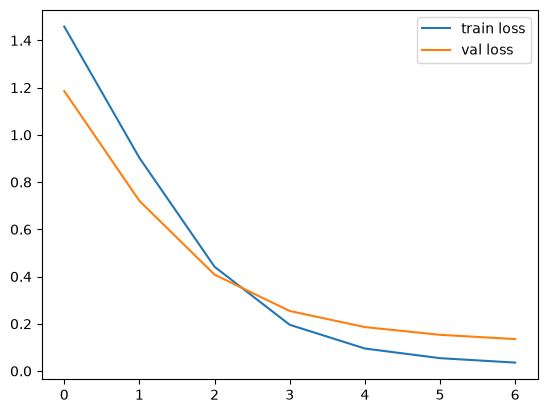

In [12]:
# Plot loss per iteration
plt.plot(r.history['loss'], label='train loss')
plt.plot(r.history['val_loss'], label='val loss')
plt.legend();

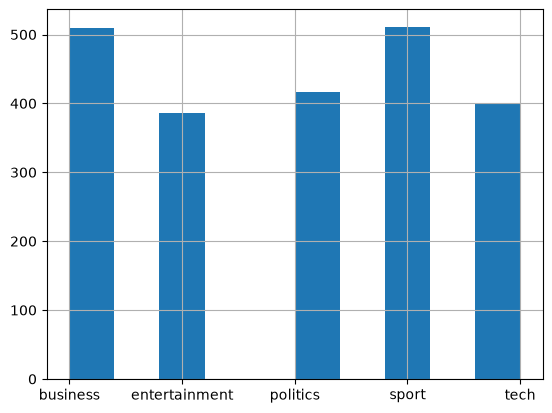

In [13]:
df['labels'].hist();

In [14]:
# Exercise: apply to sentiment analysis

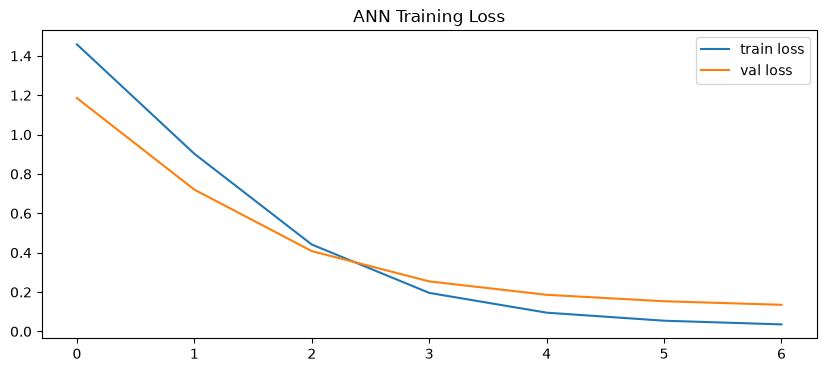

In [15]:
# 8. Plot the loss
plt.figure(figsize=(10, 4))
plt.plot(r.history['loss'], label='train loss')
plt.plot(r.history['val_loss'], label='val loss')
plt.legend()
plt.title('ANN Training Loss')
plt.show()

![](https://deeplearningcourses.com/notebooks_v3_pxl?sc=rNqZPzHeg0A0iHxXRZdjOA&n=TF2+ANN+with+TFIDF)